# Langkah 11 Anggota A — Analisis Korelasi Fitur

**Tujuan (sesuai Rencana Kerja):** menghitung matriks korelasi Pearson antarfitur di data train, lalu menandai pasangan dengan |r| > 0,8. Hasilnya menjadi bahan Anggota C untuk menjelaskan kenapa subset hasil SA bisa **terlihat tidak stabil, tetapi performanya sama**.

**Kenapa korelasi penting untuk proyek ini?** Jika dua fitur berkorelasi sangat tinggi (misalnya `centroid_mean` dan `rolloff_mean`), keduanya membawa informasi yang hampir sama. SA cukup memilih salah satunya, dan pilihannya bisa berganti-ganti antar-run atau antar-partisi. Per fitur, subset tampak berbeda; secara informasi, subset itu setara.

**Yang dikerjakan**

1. Matriks korelasi Pearson 90 × 90 di data train (aktor 1–16), untuk versi `none` dan `peak`.
2. Daftar semua pasangan fitur dengan |r| > 0,8.
3. **Kelompok fitur redundan**: fitur yang saling berkorelasi tinggi dikelompokkan dengan *hierarchical clustering* (jarak = 1 − |r|, *average linkage*, dipotong di jarak 0,2 atau setara |r| rata-rata ≥ 0,8). Setiap kelompok diberi satu fitur wakil.
4. Modul `src/redundancy.py`, agar C bisa menghitung kestabilan di tingkat kelompok (*cluster-level Jaccard*), di samping kestabilan per fitur.
5. Pemeriksaan ketahanan: korelasi Spearman (berbasis peringkat) sebagai pembanding.

**Aturan data:** hanya data train yang dipakai. Validation dan test tidak disentuh, dan label emosi tidak dipakai.

**Input dan output**

| Jenis | Lokasi (di `MyDrive/project07/`) | Keterangan |
| --- | --- | --- |
| Input | `data/features/features_none.csv`, `features_peak.csv`, `feature_names.csv` | Dari langkah 5 |
| Input | `data/splits.json`, `src/data_splits.py` | Dari langkah 7 |
| Output | `data/analysis/corr_pearson_train_{none,peak}.csv` | Matriks korelasi 90 × 90 |
| Output | `data/analysis/corr_pairs_r08_{none,peak}.csv` | Pasangan dengan |r| > 0,8 |
| Output | `data/analysis/corr_clusters_{none,peak}.csv` | Nomor kelompok redundan dan wakilnya per fitur |
| Output | `src/redundancy.py` | Fungsi Jaccard per fitur dan per kelompok |
| Output | `figures/correlation/` | 2 grafik + `correlation_summary.txt` |
| Output | `docs/README_langkah11_korelasi.md` | Dokumentasi standar |

**Prasyarat:** langkah 5 dan 7 selesai. **Perkiraan waktu:** 1–3 menit.

**Cara pakai:** jalankan sel berurutan dengan `Shift + Enter`.

## Sel 1 — Persiapan dan cek prasyarat

In [1]:
import os
import sys
import json
import hashlib
import importlib
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/project07'
except ImportError:
    BASE_DIR = os.path.abspath('project07')

DATA_DIR = os.path.join(BASE_DIR, 'data')
FEAT_DIR = os.path.join(DATA_DIR, 'features')
AN_DIR = os.path.join(DATA_DIR, 'analysis')
SRC_DIR = os.path.join(BASE_DIR, 'src')
FIG_DIR = os.path.join(BASE_DIR, 'figures', 'correlation')
DOC_DIR = os.path.join(BASE_DIR, 'docs')
CONFIG_PATH = os.path.join(BASE_DIR, 'config.json')
MODULE_PATH = os.path.join(SRC_DIR, 'redundancy.py')
for d in [AN_DIR, FIG_DIR, DOC_DIR]:
    os.makedirs(d, exist_ok=True)

wajib = [CONFIG_PATH, os.path.join(DATA_DIR, 'splits.json'), os.path.join(SRC_DIR, 'data_splits.py')] + \
        [os.path.join(FEAT_DIR, f) for f in ['features_none.csv', 'features_peak.csv', 'feature_names.csv']]
hilang = [p for p in wajib if not os.path.exists(p)]
if hilang:
    raise FileNotFoundError('Prasyarat tidak ditemukan:\n' + '\n'.join(hilang))

if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)
import data_splits as ds

with open(CONFIG_PATH, encoding='utf-8') as f:
    CONFIG = json.load(f)
S = ds.load_splits(BASE_DIR)
names = pd.read_csv(os.path.join(FEAT_DIR, 'feature_names.csv'))
F = list(names['name'])
GROUP = names.set_index('name')['group']
TABLES = {}
for v in ['none', 'peak']:
    tab = pd.read_csv(os.path.join(FEAT_DIR, f'features_{v}.csv'))
    TABLES[v], _, _ = ds.split_frames(tab, S)      # hanya train

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
                     'axes.edgecolor': '#52514e', 'axes.labelcolor': '#0b0b0b',
                     'xtick.color': '#52514e', 'ytick.color': '#52514e',
                     'axes.titlecolor': '#0b0b0b', 'font.size': 10})

print('BASE_DIR    :', BASE_DIR)
print('Baris train :', {v: len(t) for v, t in TABLES.items()}, '| aktor', sorted(int(a) for a in TABLES['none']['actor'].unique()))
print('Fitur       :', len(F))

Mounted at /content/drive
BASE_DIR    : /content/drive/MyDrive/project07
Baris train : {'none': 960, 'peak': 960} | aktor [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
Fitur       : 90


## Sel 2 — Parameter dan `config.json`

In [2]:
CORR_CONFIG = {'method': 'pearson', 'threshold_abs_r': 0.8, 'data': 'train (split utama)',
               'cluster_distance': '1 - |r|', 'cluster_linkage': 'average', 'cluster_cut_distance': 0.2,
               'representative': 'rata-rata |r| tertinggi ke anggota lain dalam kelompok',
               'robustness_check': 'spearman'}
THR = CORR_CONFIG['threshold_abs_r']
CORR_HASH = hashlib.md5(json.dumps({**CORR_CONFIG, 'features': CONFIG['features']['config_hash'],
                                    'train': S['train']}, sort_keys=True).encode()).hexdigest()[:10]
CONFIG['correlation'] = {**CORR_CONFIG, 'features_hash': CONFIG['features']['config_hash'], 'version': '1.0',
                         'config_hash': CORR_HASH, 'updated': datetime.now().strftime('%Y-%m-%d'), 'owner': 'Anggota A'}
with open(CONFIG_PATH, 'w', encoding='utf-8') as f:
    json.dump(CONFIG, f, indent=2, ensure_ascii=False)
print('config_hash correlation:', CORR_HASH)

config_hash correlation: 63bc4a61b4


## Sel 3 — Matriks korelasi dan pasangan |r| > 0,8

Korelasi Pearson mengukur seberapa lurus hubungan dua fitur: +1 = naik bersama, −1 = berlawanan arah, 0 = tidak berhubungan secara linear. Yang dihitung adalah |r|, karena korelasi negatif kuat juga berarti redundan.

In [3]:
CORR, PAIRS = {}, {}
for v, tab in TABLES.items():
    C = tab[F].corr(method='pearson')
    CORR[v] = C
    C.to_csv(os.path.join(AN_DIR, f'corr_pearson_train_{v}.csv'))
    iu = np.triu_indices(len(F), k=1)
    r = C.values[iu]
    p = pd.DataFrame({'feature_a': np.array(F)[iu[0]], 'feature_b': np.array(F)[iu[1]], 'r': r})
    p = p[p['r'].abs() > THR].copy()
    p['abs_r'] = p['r'].abs()
    p['group_a'] = p['feature_a'].map(GROUP)
    p['group_b'] = p['feature_b'].map(GROUP)
    p['jenis'] = np.where(p['group_a'] == p['group_b'], 'dalam kelompok', 'antarkelompok')
    p = p.sort_values('abs_r', ascending=False).reset_index(drop=True)
    p.round(4).to_csv(os.path.join(AN_DIR, f'corr_pairs_r08_{v}.csv'), index=False)
    PAIRS[v] = p
    print(f"{v}: {len(p)} pasangan |r| > {THR} dari {len(r)} pasangan "
          f"({(p['jenis'] == 'dalam kelompok').sum()} dalam kelompok, {(p['jenis'] == 'antarkelompok').sum()} antarkelompok)")

P = PAIRS['none']
print('\n15 pasangan dengan |r| tertinggi (versi none):')
display(P.head(15)[['feature_a', 'feature_b', 'r', 'group_a', 'group_b']].round(3))
terlibat = pd.Series(list(P['feature_a']) + list(P['feature_b'])).value_counts()
print(f'Fitur yang punya minimal satu pasangan |r| > {THR}: {len(terlibat)} dari {len(F)}')
print('Paling banyak pasangan:', ', '.join(f'{n} ({c})' for n, c in terlibat.head(8).items()))

none: 39 pasangan |r| > 0.8 dari 4005 pasangan (28 dalam kelompok, 11 antarkelompok)
peak: 36 pasangan |r| > 0.8 dari 4005 pasangan (25 dalam kelompok, 11 antarkelompok)

15 pasangan dengan |r| tertinggi (versi none):


,feature_a,feature_b,r,group_a,group_b
0,rms_std,rms_max,0.987,energi,energi
1,rms_mean,rms_std,0.984,energi,energi
2,f0_std,f0_range,0.972,prosodi,prosodi
3,rms_mean,rms_max,0.964,energi,energi
4,zcr_std,centroid_std,0.942,zcr,spektral
5,centroid_mean,rolloff_mean,0.935,spektral,spektral
6,f0_mean,f0_p05,0.934,prosodi,prosodi
7,mfcc13_std,dmfcc13_std,0.926,mfcc,delta_mfcc
8,mfcc12_std,dmfcc12_std,0.915,mfcc,delta_mfcc
9,zcr_mean,centroid_mean,0.912,zcr,spektral


Fitur yang punya minimal satu pasangan |r| > 0.8: 45 dari 90
Paling banyak pasangan: centroid_mean (3), f0_mean (3), f0_p95 (3), f0_std (2), rms_std (2), chroma02_mean (2), mfcc13_std (2), mfcc12_std (2)


## Sel 4 — Kelompok fitur redundan

Fitur yang saling berkorelasi tinggi digabung menjadi satu kelompok. Kelompok berisi satu fitur berarti fitur itu tidak punya "pengganti" yang dekat. Kelompok berisi banyak fitur berarti anggotanya bisa saling menggantikan, sehingga SA bebas memilih salah satunya.

In [4]:
CLUST = {}
for v in ['none', 'peak']:
    A = CORR[v].abs().values.copy()
    np.fill_diagonal(A, 1.0)
    D = np.clip(1.0 - A, 0, None)
    np.fill_diagonal(D, 0.0)
    Z = linkage(squareform(D, checks=False), method=CORR_CONFIG['cluster_linkage'])
    lab = fcluster(Z, t=CORR_CONFIG['cluster_cut_distance'], criterion='distance')
    # Penomoran ulang: kelompok terbesar dulu, lalu urutan fitur pertama
    df = pd.DataFrame({'index': range(len(F)), 'name': F, 'group': [GROUP[n] for n in F], 'raw': lab})
    ukuran = df['raw'].value_counts()
    urut = sorted(ukuran.index, key=lambda c: (-ukuran[c], df.index[df['raw'] == c][0]))
    df['cluster'] = df['raw'].map({c: i + 1 for i, c in enumerate(urut)})
    df['cluster_size'] = df['cluster'].map(df['cluster'].value_counts())
    wakil, mean_r = {}, {}
    for c, sub in df.groupby('cluster'):
        idx = sub['index'].tolist()
        if len(idx) == 1:
            wakil[c] = sub['name'].iloc[0]
            mean_r[sub['name'].iloc[0]] = np.nan
            continue
        blok = A[np.ix_(idx, idx)]
        m = (blok.sum(axis=1) - 1) / (len(idx) - 1)
        for n, val in zip(sub['name'], m):
            mean_r[n] = float(val)
        wakil[c] = sub['name'].iloc[int(np.argmax(m))]
    df['mean_abs_r_in_cluster'] = df['name'].map(mean_r).round(4)
    df['representative'] = df['cluster'].map(wakil)
    df['is_representative'] = df['name'] == df['representative']
    df = df.drop(columns='raw')
    df.to_csv(os.path.join(AN_DIR, f'corr_clusters_{v}.csv'), index=False)
    CLUST[v] = df
    print(f"{v}: {df['cluster'].nunique()} kelompok untuk {len(F)} fitur | "
          f"{(df['cluster_size'] > 1).groupby(df['cluster']).first().sum()} kelompok berisi ≥ 2 fitur | "
          f"{(df['cluster_size'] == 1).sum()} fitur berdiri sendiri")

CL = CLUST['none']
multi = CL[CL['cluster_size'] > 1].groupby('cluster').agg(
    ukuran=('name', 'size'), wakil=('representative', 'first'),
    kelompok_fitur=('group', lambda g: ', '.join(sorted(set(g)))),
    anggota=('name', lambda n: ', '.join(n)))
print('\nKelompok redundan berisi ≥ 2 fitur (versi none):')
pd.set_option('display.max_colwidth', 120)
display(multi)

none: 66 kelompok untuk 90 fitur | 17 kelompok berisi ≥ 2 fitur | 49 fitur berdiri sendiri
peak: 68 kelompok untuk 90 fitur | 16 kelompok berisi ≥ 2 fitur | 52 fitur berdiri sendiri

Kelompok redundan berisi ≥ 2 fitur (versi none):


,ukuran,wakil,kelompok_fitur,anggota
cluster,,,,
1,4,dmfcc13_std,"delta_mfcc, mfcc","mfcc12_std, mfcc13_std, dmfcc12_std, dmfcc13_std"
2,3,f0_mean,prosodi,"f0_mean, f0_p05, f0_p95"
3,3,rms_std,energi,"rms_mean, rms_std, rms_max"
4,3,centroid_mean,"spektral, zcr","zcr_mean, centroid_mean, rolloff_mean"
5,3,centroid_std,"spektral, zcr","zcr_std, centroid_std, rolloff_std"
6,3,contrast4_mean,contrast,"contrast4_mean, contrast5_mean, contrast6_mean"
7,2,mfcc02_std,"delta_mfcc, mfcc","mfcc02_std, dmfcc02_std"
8,2,mfcc04_std,"delta_mfcc, mfcc","mfcc04_std, dmfcc04_std"
9,2,mfcc10_std,"delta_mfcc, mfcc","mfcc10_std, dmfcc10_std"


## Sel 5 — Tulis dan uji modul `src/redundancy.py`

In [5]:
%%writefile {MODULE_PATH}
"""
redundancy.py — Kelompok fitur redundan (berkorelasi tinggi) untuk Proyek 07.

Penanggung jawab : Anggota A
Versi            : 1.0

Dibuat di langkah 11 (analisis korelasi). Dipakai Anggota C untuk analisis stabilitas:
dua subset bisa tampak berbeda per fitur, tetapi sama jika fitur-fiturnya berasal
dari kelompok redundan yang sama (misalnya centroid_mean dan rolloff_mean).

Contoh:
    import redundancy as rd
    cl = rd.load_clusters(BASE_DIR)                     # DataFrame: index, name, cluster, ...
    rd.jaccard([0, 5, 9], [0, 6, 9])                    # Jaccard per fitur
    rd.cluster_jaccard([0, 5, 9], [0, 6, 9], cl)        # Jaccard per kelompok redundan
"""
import os

import numpy as np
import pandas as pd

REDUNDANCY_VERSION = '1.0'


def load_clusters(base_dir, version='none'):
    """Baca data/analysis/corr_clusters_{version}.csv."""
    return pd.read_csv(os.path.join(base_dir, 'data', 'analysis', f'corr_clusters_{version}.csv'))


def to_clusters(indices, clusters):
    """Ubah daftar indeks fitur (0-89) menjadi himpunan nomor kelompok redundan."""
    m = dict(zip(clusters['index'].astype(int), clusters['cluster'].astype(int)))
    return {m[int(i)] for i in indices}


def jaccard(a, b):
    """Indeks Jaccard dua himpunan: |A ∩ B| / |A ∪ B| (1 jika keduanya kosong)."""
    a, b = set(a), set(b)
    return 1.0 if not (a | b) else len(a & b) / len(a | b)


def cluster_jaccard(indices_a, indices_b, clusters):
    """Jaccard dua subset fitur setelah diubah ke kelompok redundan."""
    return jaccard(to_clusters(indices_a, clusters), to_clusters(indices_b, clusters))


def mean_pairwise(subsets, fn):
    """Rata-rata fn(a, b) untuk semua pasangan subset (misalnya 15 run stabilitas)."""
    vals = [fn(subsets[i], subsets[j]) for i in range(len(subsets)) for j in range(i + 1, len(subsets))]
    return float(np.mean(vals)) if vals else float('nan')


Writing /content/drive/MyDrive/project07/src/redundancy.py


In [6]:
import redundancy as rd
importlib.reload(rd)
uji = []
def u(nama, kondisi, detail=''):
    uji.append(f"[{'OK' if kondisi else 'CEK'}] {nama}" + (f' — {detail}' if detail else ''))

cl = rd.load_clusters(BASE_DIR, 'none')
u('jaccard: himpunan sama = 1, terpisah = 0', rd.jaccard([1, 2], [2, 1]) == 1 and rd.jaccard([1], [2]) == 0)
u('jaccard: {1,2,3} vs {2,3,4} = 0,5', abs(rd.jaccard([1, 2, 3], [2, 3, 4]) - 0.5) < 1e-12)
big = cl[cl['cluster_size'] > 1]
if len(big):
    c0 = big['cluster'].iloc[0]
    anggota = cl.loc[cl['cluster'] == c0, 'index'].tolist()
    a, b = [anggota[0]], [anggota[1]]
    u('Dua fitur dari kelompok redundan yang sama: Jaccard per fitur 0, per kelompok 1',
      rd.jaccard(a, b) == 0 and rd.cluster_jaccard(a, b, cl) == 1, f'{F[a[0]]} vs {F[b[0]]}')
else:
    u('Ada kelompok redundan untuk diuji', False, 'tidak ada kelompok berisi ≥ 2 fitur')
u('mean_pairwise menghitung rata-rata semua pasangan',
  abs(rd.mean_pairwise([[1], [1], [2]], rd.jaccard) - (1 + 0 + 0) / 3) < 1e-12)
for x in uji:
    print(x)

[OK] jaccard: himpunan sama = 1, terpisah = 0
[OK] jaccard: {1,2,3} vs {2,3,4} = 0,5
[OK] Dua fitur dari kelompok redundan yang sama: Jaccard per fitur 0, per kelompok 1 — mfcc02_std vs dmfcc02_std
[OK] mean_pairwise menghitung rata-rata semua pasangan


## Sel 6 — Verifikasi

In [7]:
laporan = []
def cek(nama, kondisi, detail=''):
    laporan.append(f"[{'OK' if kondisi else 'CEK'}] {nama}" + (f' — {detail}' if detail else ''))

tr = TABLES['none']
cek('Hanya data train (aktor 1-16, 960 baris)', sorted(int(a) for a in tr['actor'].unique()) == S['train'] and len(tr) == 960,
    f"{len(tr)} baris")
C = CORR['none'].values
cek('Matriks 90 × 90, simetris, diagonal 1, tanpa NaN',
    C.shape == (90, 90) and np.allclose(C, C.T) and np.allclose(np.diag(C), 1) and np.isfinite(C).all())
cek('Setiap fitur masuk tepat satu kelompok redundan', CL['name'].tolist() == F and CL['cluster'].notna().all())
same = (P['feature_a'].map(CL.set_index('name')['cluster']) == P['feature_b'].map(CL.set_index('name')['cluster']))
cek('Sebagian besar pasangan |r| > 0,8 berada dalam kelompok yang sama', same.mean() >= 0.8 if len(P) else True,
    f'{same.mean():.0%} dari {len(P)} pasangan' if len(P) else 'tidak ada pasangan')
lin = [CL.loc[CL['cluster'] == c, 'mean_abs_r_in_cluster'].min() for c in CL.loc[CL['cluster_size'] > 1, 'cluster'].unique()]
cek('Rata-rata |r| setiap anggota ke kelompoknya ≥ 0,8 (sesuai batas potong)', all(x >= 0.8 - 1e-9 for x in lin),
    f'minimum {min(lin):.3f}' if lin else 'tidak ada kelompok ≥ 2')
skala = names.loc[names['scale_dependent'].astype(bool), 'name'].tolist()
diff = (CORR['none'] - CORR['peak']).abs()
diff_ne = diff.drop(index=skala, columns=skala).values
cek('Versi none dan peak hanya berbeda pada korelasi yang melibatkan fitur energi', np.nanmax(diff_ne) < 1e-3,
    f'selisih maks di luar fitur energi {np.nanmax(diff_ne):.2e}; di fitur energi {diff.loc[skala].values.max():.3f}')
SP = tr[F].corr(method='spearman')
n_sp = int(((SP.abs().values > THR) & np.triu(np.ones_like(C, bool), 1)).sum())
irisan = len(set(zip(P['feature_a'], P['feature_b'])) & {(F[i], F[j]) for i, j in zip(*np.where(np.triu(SP.abs().values > THR, 1)))})
cek('Pemeriksaan Spearman: sebagian besar pasangan Pearson juga tinggi di Spearman',
    irisan >= 0.7 * len(P) if len(P) else True, f'Pearson {len(P)}, Spearman {n_sp}, sama {irisan}')
cek('Uji modul redundancy.py lolos', all(x.startswith('[OK') for x in uji), f"{sum(x.startswith('[OK') for x in uji)}/{len(uji)}")
for x in laporan:
    print(x)
n_ok = sum(x.startswith('[OK') for x in laporan)
print(f'\n{n_ok}/{len(laporan)} OK')

[OK] Hanya data train (aktor 1-16, 960 baris) — 960 baris
[OK] Matriks 90 × 90, simetris, diagonal 1, tanpa NaN
[OK] Setiap fitur masuk tepat satu kelompok redundan
[CEK] Sebagian besar pasangan |r| > 0,8 berada dalam kelompok yang sama — 69% dari 39 pasangan
[OK] Rata-rata |r| setiap anggota ke kelompoknya ≥ 0,8 (sesuai batas potong) — minimum 0.807
[OK] Versi none dan peak hanya berbeda pada korelasi yang melibatkan fitur energi — selisih maks di luar fitur energi 9.88e-05; di fitur energi 0.747
[OK] Pemeriksaan Spearman: sebagian besar pasangan Pearson juga tinggi di Spearman — Pearson 39, Spearman 37, sama 36
[OK] Uji modul redundancy.py lolos — 4/4

7/8 OK


## Sel 7 — Grafik

- `corr_01`: matriks korelasi 90 × 90 (versi none), diurutkan per kelompok fitur. Oranye = korelasi positif, biru = negatif, abu-abu muda = tidak berhubungan.
- `corr_02`: jumlah pasangan |r| > 0,8 di dalam dan antarkelompok fitur.

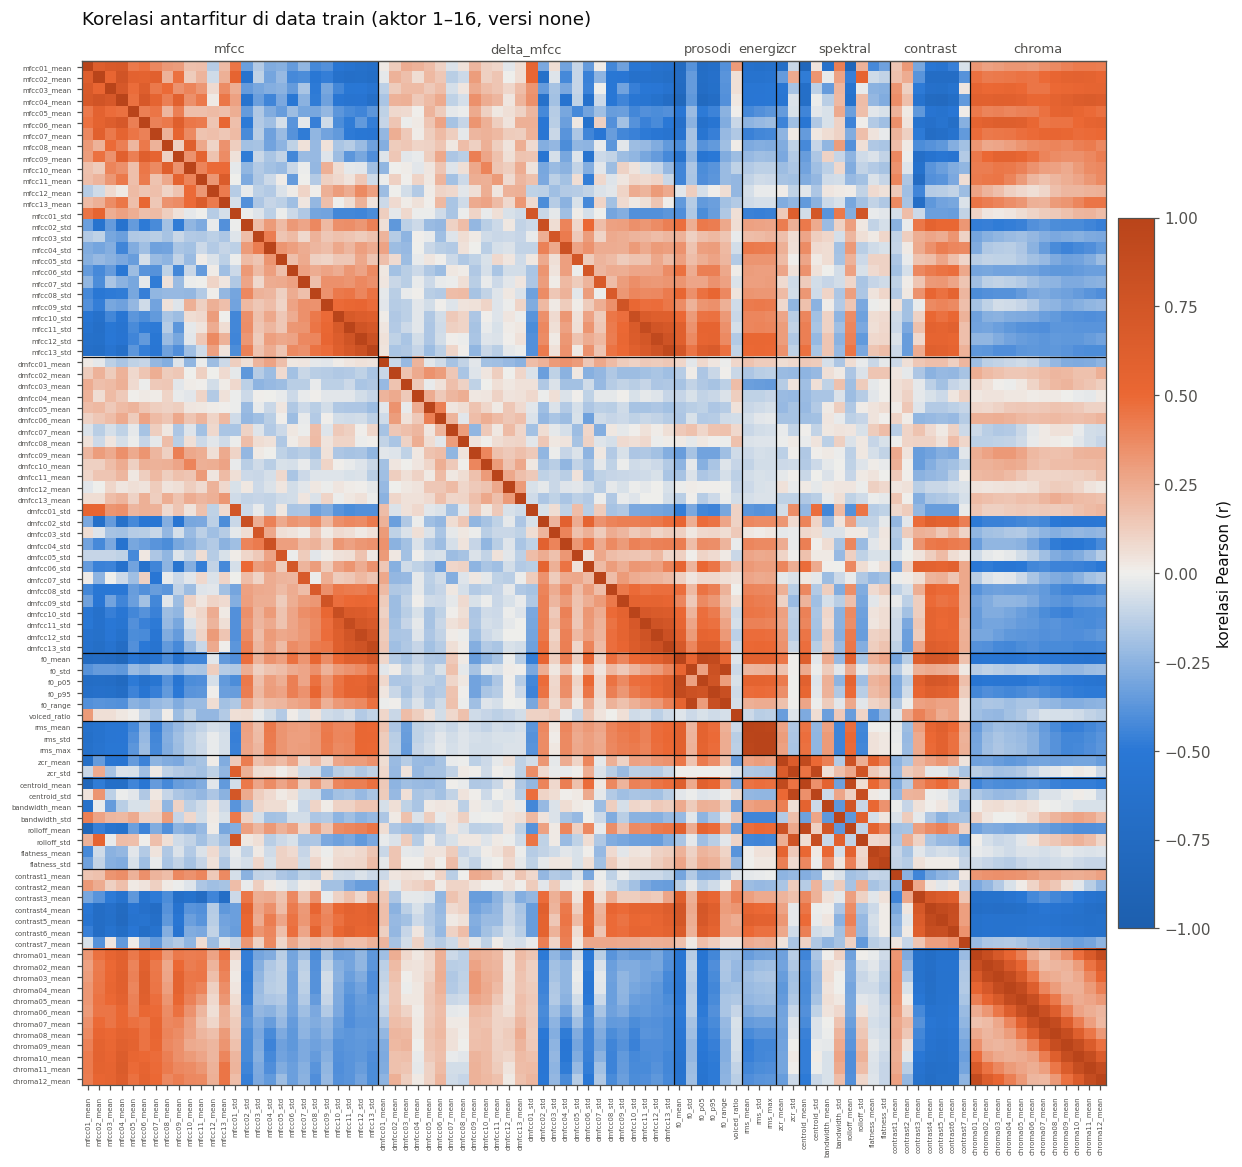

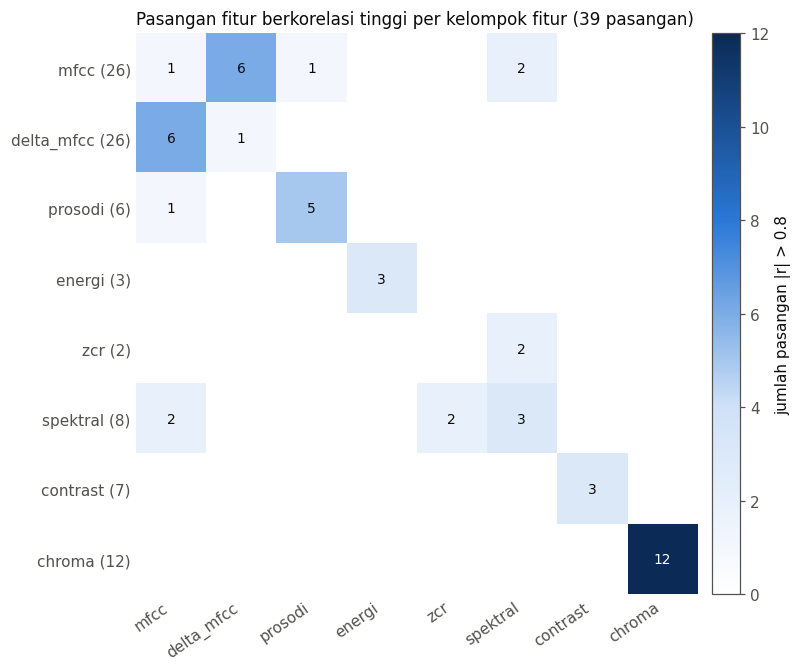

In [8]:
DIV = LinearSegmentedColormap.from_list('div', ['#1d5fae', '#2a78d6', '#f0efec', '#eb6834', '#b9441a'])
urut_grp = list(dict.fromkeys(names['group']))
batas = np.cumsum([int((names['group'] == g).sum()) for g in urut_grp])
fig, ax = plt.subplots(figsize=(12, 10.5), layout='constrained')
im = ax.imshow(CORR['none'].values, cmap=DIV, vmin=-1, vmax=1, interpolation='nearest')
for b in batas[:-1]:
    ax.axhline(b - 0.5, color='#0b0b0b', lw=0.8)
    ax.axvline(b - 0.5, color='#0b0b0b', lw=0.8)
ax.set_xticks(range(len(F)))
ax.set_xticklabels(F, rotation=90, fontsize=4.6)
ax.set_yticks(range(len(F)))
ax.set_yticklabels(F, fontsize=4.6)
mid = np.concatenate([[0], batas[:-1]]) + np.diff(np.concatenate([[0], batas])) / 2 - 0.5
ax2 = ax.secondary_xaxis('top')
ax2.set_xticks(mid)
ax2.set_xticklabels(urut_grp, fontsize=8.5)
ax2.tick_params(length=0)
cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.01)
cb.set_label('korelasi Pearson (r)')
ax.set_title('Korelasi antarfitur di data train (aktor 1–16, versi none)', loc='left', fontsize=12, pad=24)
fig.savefig(os.path.join(FIG_DIR, 'corr_01_matriks_korelasi.png'))
plt.show()

M = pd.DataFrame(0, index=urut_grp, columns=urut_grp)
for _, r in P.iterrows():
    a, b = r['group_a'], r['group_b']
    M.loc[a, b] += 1
    if a != b:
        M.loc[b, a] += 1
BLUES = LinearSegmentedColormap.from_list('biru', ['#ffffff', '#cfe1f7', '#2a78d6', '#0b2a55'])
fig, ax = plt.subplots(figsize=(7.5, 6), layout='constrained')
im = ax.imshow(M.values, cmap=BLUES, vmin=0, vmax=max(1, M.values.max()))
ax.set_xticks(range(len(urut_grp)))
ax.set_xticklabels(urut_grp, rotation=35, ha='right')
ax.set_yticks(range(len(urut_grp)))
ax.set_yticklabels([f'{g} ({int((names["group"] == g).sum())})' for g in urut_grp])
for i in range(len(urut_grp)):
    for j in range(len(urut_grp)):
        v = int(M.values[i, j])
        if v:
            ax.text(j, i, str(v), ha='center', va='center', fontsize=9,
                    color='white' if v > 0.55 * M.values.max() else '#0b0b0b')
ax.tick_params(length=0)
for s_ in ax.spines.values():
    s_.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
cb.set_label(f'jumlah pasangan |r| > {THR}')
ax.set_title(f'Pasangan fitur berkorelasi tinggi per kelompok fitur ({len(P)} pasangan)', loc='left', fontsize=11)
fig.savefig(os.path.join(FIG_DIR, 'corr_02_pasangan_per_kelompok.png'))
plt.show()

## Sel 8 — Ringkasan dan dokumentasi standar

In [9]:
tgl = datetime.now().strftime('%Y-%m-%d')
n_multi = CL.loc[CL['cluster_size'] > 1, 'cluster'].nunique()
n_red = int((CL['cluster_size'] > 1).sum())
ringkas = [
    f'Ringkasan analisis korelasi (langkah 11, {tgl})',
    f"config_hash correlation: {CORR_HASH} | fitur: {CONFIG['features']['config_hash']}",
    '',
    f'Data: train split utama (aktor 1-16, {len(tr)} baris), 90 fitur, Pearson',
    f"Pasangan |r| > {THR}: none {len(PAIRS['none'])}, peak {len(PAIRS['peak'])} (dari {90 * 89 // 2})",
    f"  versi none: {(P['jenis'] == 'dalam kelompok').sum()} dalam kelompok fitur, {(P['jenis'] == 'antarkelompok').sum()} antarkelompok",
    f'  fitur dengan minimal satu pasangan: {len(terlibat)} dari 90',
    f'Spearman |r| > {THR}: {n_sp} pasangan, {irisan} sama dengan Pearson',
    '',
    f"Kelompok redundan (versi none): {CL['cluster'].nunique()} kelompok; {n_multi} kelompok berisi >= 2 fitur ({n_red} fitur); {int((CL['cluster_size'] == 1).sum())} fitur berdiri sendiri",
] + [f"  K{c} ({r_['ukuran']} fitur, wakil {r_['wakil']}): {r_['anggota']}" for c, r_ in multi.iterrows()] + [
    '',
    '15 pasangan |r| tertinggi (versi none):',
] + [f"  {r_['feature_a']} ~ {r_['feature_b']}: r = {r_['r']:.3f}" for _, r_ in P.head(15).iterrows()] + [
    '',
    f'Verifikasi: {n_ok}/{len(laporan)} OK',
] + ['  ' + x for x in laporan]
teks = '\n'.join(ringkas)
print(teks)
with open(os.path.join(FIG_DIR, 'correlation_summary.txt'), 'w', encoding='utf-8') as fh:
    fh.write(teks + '\n')

tabel_k = '\n'.join(f"| K{c} | {r_['ukuran']} | `{r_['wakil']}` | {r_['kelompok_fitur']} | {r_['anggota']} |" for c, r_ in multi.iterrows())
tabel_p = '\n'.join(f"| `{r_['feature_a']}` | `{r_['feature_b']}` | {r_['r']:.3f} |" for _, r_ in P.head(15).iterrows())
readme = f'''# Langkah 11 — Analisis Korelasi Fitur

Penanggung jawab: Anggota A · Versi: 1.0 · Dijalankan: {tgl} · config_hash: `{CORR_HASH}` (fitur `{CONFIG['features']['config_hash']}`)

## Tujuan

Menghitung korelasi Pearson antarfitur di data train dan menandai pasangan |r| > {THR}, sebagai bahan untuk menjelaskan kenapa subset hasil SA dapat tampak tidak stabil tetapi performanya setara. Hanya data train yang dipakai; label emosi tidak dipakai.

## Output

| File | Isi |
| --- | --- |
| `data/analysis/corr_pearson_train_{{none,peak}}.csv` | Matriks korelasi 90 × 90 |
| `data/analysis/corr_pairs_r08_{{none,peak}}.csv` | `feature_a, feature_b, r, abs_r, group_a, group_b, jenis` |
| `data/analysis/corr_clusters_{{none,peak}}.csv` | `index, name, group, cluster, cluster_size, mean_abs_r_in_cluster, representative, is_representative` |
| `src/redundancy.py` | `load_clusters`, `to_clusters`, `jaccard`, `cluster_jaccard`, `mean_pairwise` |
| `figures/correlation/` | `corr_01_matriks_korelasi.png`, `corr_02_pasangan_per_kelompok.png`, `correlation_summary.txt` |

## Hasil

- Pasangan |r| > {THR}: **{len(P)}** dari {90 * 89 // 2} pasangan (versi none); {len(terlibat)} dari 90 fitur punya minimal satu pasangan.
- Kelompok redundan: **{CL['cluster'].nunique()} kelompok** untuk 90 fitur; {n_multi} kelompok berisi ≥ 2 fitur ({n_red} fitur), {int((CL['cluster_size'] == 1).sum())} fitur berdiri sendiri.
- Versi none dan peak hanya berbeda pada korelasi yang melibatkan 3 fitur energi.

### Kelompok redundan berisi ≥ 2 fitur (versi none)

| Kelompok | Ukuran | Wakil | Kelompok fitur | Anggota |
| --- | --- | --- | --- | --- |
{tabel_k}

### 15 pasangan dengan |r| tertinggi

| Fitur A | Fitur B | r |
| --- | --- | --- |
{tabel_p}

## Cara memakai (Anggota C: analisis stabilitas)

```python
import sys
sys.path.insert(0, BASE_DIR + '/src')
import redundancy as rd
cl = rd.load_clusters(BASE_DIR, 'none')           # atau 'peak', ikut versi pilihan B
subsets = [...]                                    # daftar indeks fitur per run dari subsets.json
j_fitur = rd.mean_pairwise(subsets, rd.jaccard)
j_kelompok = rd.mean_pairwise(subsets, lambda a, b: rd.cluster_jaccard(a, b, cl))
# j_kelompok jauh lebih tinggi daripada j_fitur -> SA memilih fitur berbeda dari kelompok redundan yang sama
```

## Verifikasi

{n_ok}/{len(laporan)} pemeriksaan OK.

''' + '\n'.join(f'- {x}' for x in laporan) + f'''

## Keterbatasan

- Pearson hanya menangkap hubungan linear; pemeriksaan Spearman dipakai sebagai pembanding.
- Batas |r| > {THR} dan potongan kelompok di jarak 0,2 adalah konvensi, bukan nilai mutlak.
- Korelasi dihitung di train split utama; di partisi lain nilainya bisa sedikit berbeda.

## Riwayat versi

| Versi | Tanggal | Perubahan |
| --- | --- | --- |
| 1.0 | {tgl} | Versi pertama |
'''
with open(os.path.join(DOC_DIR, 'README_langkah11_korelasi.md'), 'w', encoding='utf-8') as fh:
    fh.write(readme)
print('\nTersimpan:', os.path.join(FIG_DIR, 'correlation_summary.txt'))
print('Tersimpan:', os.path.join(DOC_DIR, 'README_langkah11_korelasi.md'))

Ringkasan analisis korelasi (langkah 11, 2026-11-21)
config_hash correlation: 63bc4a61b4 | fitur: 0c3114fc78

Data: train split utama (aktor 1-16, 960 baris), 90 fitur, Pearson
Pasangan |r| > 0.8: none 39, peak 36 (dari 4005)
  versi none: 28 dalam kelompok fitur, 11 antarkelompok
  fitur dengan minimal satu pasangan: 45 dari 90
Spearman |r| > 0.8: 37 pasangan, 36 sama dengan Pearson

Kelompok redundan (versi none): 66 kelompok; 17 kelompok berisi >= 2 fitur (41 fitur); 49 fitur berdiri sendiri
  K1 (4 fitur, wakil dmfcc13_std): mfcc12_std, mfcc13_std, dmfcc12_std, dmfcc13_std
  K2 (3 fitur, wakil f0_mean): f0_mean, f0_p05, f0_p95
  K3 (3 fitur, wakil rms_std): rms_mean, rms_std, rms_max
  K4 (3 fitur, wakil centroid_mean): zcr_mean, centroid_mean, rolloff_mean
  K5 (3 fitur, wakil centroid_std): zcr_std, centroid_std, rolloff_std
  K6 (3 fitur, wakil contrast4_mean): contrast4_mean, contrast5_mean, contrast6_mean
  K7 (2 fitur, wakil mfcc02_std): mfcc02_std, dmfcc02_std
  K8 (2 fitur,

## Selesai — yang dilakukan setelah notebook ini

1. Pastikan semua uji di Sel 5 dan verifikasi di Sel 6 bertanda **OK**.
2. Simpan notebook ke `project07/notebooks/Langkah11_AnggotaA_Korelasi_Fitur.ipynb`.
3. Kirim ke saya untuk Log Kerja: isi `correlation_summary.txt` serta screenshot grafik `corr_01` dan `corr_02`.